## Objectif du notebook
Nous utilisons l'analyse exploratoire pour comprendre la distribution, la tendance centrale, la dispersion, la saisonnalité et les relations entre les variables avant de choisir tout nettoyage ou modèle. C'est une étape directive et pas seulement des graphiques (DataMining-Course-02, pages 35–51 ; DataMining-Course-04, pages 1–4 et 6–8).

In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter was started in the project root or notebooks/.
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
PROJECT_ROOT = next((p for p in _candidates if (p / "data" / "raw" / "era5_algeria_raw.nc").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter from the project root or notebooks/ folder.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from climate_utils import (
    load_masked_dataset, make_algeria_mask, load_boundary,
    regional_time_series, to_analysis_units, area_weighted_mean,
)

plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42
print("Project root:", PROJECT_ROOT)
ds, mask, algeria = load_masked_dataset(PROJECT_ROOT)
regional_raw = regional_time_series(ds, mask)
regional = to_analysis_units(regional_raw)
print("Forme de la série régionale:", regional.shape)
print("Plage temporelle:", regional.index.min(), "à", regional.index.max())
display(regional.head())

Project root: C:\Users\hp\Downloads\Climate_Data_Mining_Algeria\Climate_Data_Mining_Algeria\Climate_Data_Mining
Forme de la série régionale: (141, 13)
Plage temporelle: 2015-01-01 00:00:00 à 2026-09-01 00:00:00


,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp,wind10_speed
valid_time,,,,,,,,,,,,,
2015-01-01,-4.364057,10.701772,-3.991765e+05,9.819455e+06,-8.245064e+06,-1.377916e+06,0.006055,-0.000159,-0.712325,-0.994528,95787.853969,0.208876,1.223312
2015-02-01,-2.733047,13.689666,-8.032164e+05,1.162284e+07,-8.601606e+06,-2.326944e+06,0.014036,-0.000321,0.447093,-0.950187,95121.438190,0.523205,1.050118
2015-03-01,-2.354171,16.779881,-1.022070e+06,1.451208e+07,-9.782352e+06,-3.588566e+06,0.013602,-0.000409,-0.570373,-0.782152,95249.882817,0.362976,0.968033
2015-04-01,-4.934355,24.797454,-5.486119e+05,1.742655e+07,-1.187398e+07,-4.572212e+06,0.008024,-0.000219,-0.934921,0.405604,95201.607103,0.033328,1.019113
2015-05-01,-1.789006,28.971948,-5.234638e+05,1.854018e+07,-1.249433e+07,-5.203514e+06,0.005708,-0.000209,-1.045647,-0.369564,94972.872490,0.083865,1.109034


## Qualité des données et valeurs manquantes
Nous calculons les valeurs manquantes uniquement dans les cellules du polygone. Les cellules situées en dehors des frontières de l'Algérie ne sont pas des observations manquantes, et ne doivent pas être confondues avec les valeurs manquantes de la source. Nous montrons également le nombre de points manquants pour chaque variable avant de choisir toute méthode de traitement.

In [29]:
quality_rows = []
for name in ds.data_vars:
    inside = ds[name].where(mask)
    total_inside_values = int(mask.sum().values) * ds.sizes["valid_time"]
    missing_inside = int(inside.isnull().where(mask).sum().values)
    quality_rows.append({"variable": name, "units": ds[name].attrs.get("units", ""),
                         "missing_inside_polygon": missing_inside,
                         "missing_percent_inside_polygon": 100 * missing_inside / total_inside_values})
quality = pd.DataFrame(quality_rows).sort_values("missing_percent_inside_polygon", ascending=False)
display(quality)

,variable,units,missing_inside_polygon,missing_percent_inside_polygon
0,d2m,K,1692,0.056
1,t2m,K,1692,0.056
2,slhf,J m**-2,1692,0.056
3,ssr,J m**-2,1692,0.056
4,str,J m**-2,1692,0.056
5,sshf,J m**-2,1692,0.056
6,ro,m,1692,0.056
7,e,m of water equivalent,1692,0.056
8,u10,m s**-1,1692,0.056
9,v10,m s**-1,1692,0.056


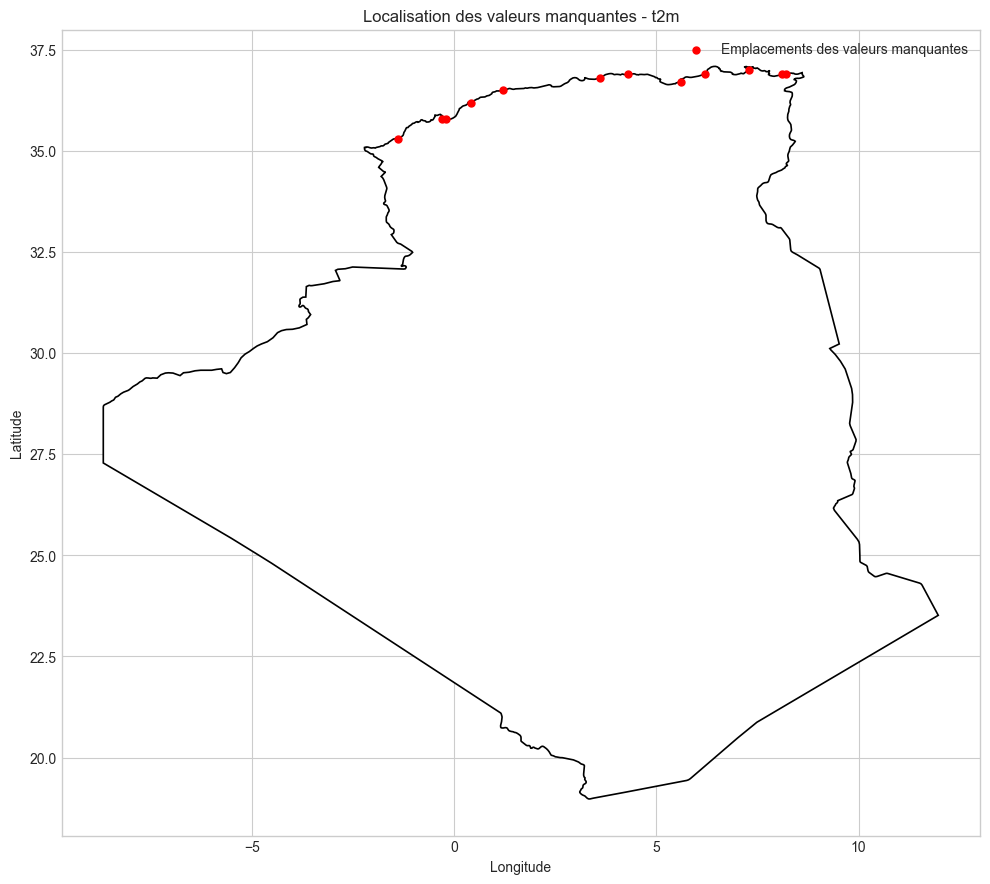

In [18]:
import matplotlib.pyplot as plt
import numpy as np

variable = "t2m"

# Identifier les points géographiques qui contiennent
# au moins une valeur manquante pendant la période
missing = ds[variable].isnull().any(dim="valid_time")

# Garder uniquement les points situés en Algérie
missing = missing.where(mask, False)

# Récupérer les coordonnées des points manquants
missing_lat, missing_lon = np.where(missing.values)

latitudes = ds.latitude.values[missing_lat]
longitudes = ds.longitude.values[missing_lon]

# Charger la frontière de l'Algérie
geometry = load_boundary()

# Créer la figure
fig, ax = plt.subplots(figsize=(10, 10))

# Fond blanc
ax.set_facecolor("white")

# Dessiner les frontières de l'Algérie
polygons = (
    [geometry]
    if geometry.geom_type == "Polygon"
    else list(geometry.geoms)
)

for polygon in polygons:
    x, y = polygon.exterior.xy
    ax.fill(x, y, facecolor="white", edgecolor="black", linewidth=1.2)

# Afficher les valeurs manquantes avec des points rouges
ax.scatter(
    longitudes,
    latitudes,
    color="red",
    s=25,
    marker="o",
    label="Emplacements des valeurs manquantes",
    zorder=5
)

ax.set_title(f"Localisation des valeurs manquantes - {variable}")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="upper right")

ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## Analyse univariée : tendance centrale et dispersion
La moyenne est affectée par les valeurs extrêmes ; la médiane est plus robuste pour l'asymétrie, et le mode est généralement moins utile pour les variables continues. Nous affichons un résumé numérique, puis un graphique de la distribution. Les statistiques ici concernent la moyenne régionale mensuelle pondérée approximativement par la surface, et non la distribution de toutes les cellules de la grille.

In [27]:
pd.set_option('display.float_format', '{:.3f}'.format)
focus = regional[[c for c in ["t2m", "d2m", "tp", "wind10_speed", "sp","slhf","ssr","str","sshf","ro","e"] if c in regional.columns]].copy() #Température/Humidité/Précipitations/Conditions du vent/Pression atmosphérique à la surface
summary = pd.DataFrame({
    "mean": focus.mean(), "median": focus.median(), "mode_first": focus.mode().iloc[0],
    "std_sample": focus.std(ddof=1), "min": focus.min(),
    "Q1": focus.quantile(0.25), "Q3": focus.quantile(0.75), "max": focus.max(),
    "missing": focus.isna().sum(),
})
summary["IQR"] = summary["Q3"] - summary["Q1"]
display(summary.round(3))

'''Indicateur	Signification
Mean	Moyenne
Median	Valeur centrale
Mode	Valeur la plus fréquente
Std_sample	Écart-type, mesure de dispersion
Min / Max	Valeurs minimale et maximale
Q1 / Q3	Premier et troisième quartiles
IQR	Écart interquartile (Q3 − Q1)
Missing	Nombre de valeurs manquantes
'''

,mean,median,mode_first,std_sample,min,Q1,Q3,max,missing,IQR
t2m,24.020,24.595,9.616,7.983,9.616,16.793,31.670,35.695,0,14.877
d2m,1.407,1.452,-5.490,3.673,-5.490,-1.749,3.957,12.234,0,5.706
tp,0.159,0.109,0.009,0.131,0.009,0.061,0.227,0.734,0,0.166
wind10_speed,1.375,1.425,0.175,0.619,0.175,0.913,1.774,3.053,0,0.862
sp,95162.853,95060.154,94675.093,322.086,94675.093,94911.570,95393.255,96210.956,0,481.685
slhf,-465391.063,-425533.540,-1216375.551,229269.615,-1216375.551,-610889.237,-318956.184,-99069.287,0,291933.053
ssr,13519862.263,14302864.947,4916550.297,3912377.249,4916550.297,10073318.012,17059376.885,18701018.167,0,6986058.873
str,-9559678.102,-9924335.261,-12494334.649,2292274.450,-12494334.649,-11333213.889,-8389333.378,-3938398.967,0,2943880.511
sshf,-3389079.071,-3657448.429,-5479316.031,1582928.921,-5479316.031,-4927831.987,-1774473.731,-496277.735,0,3153358.255
ro,0.003,0.002,0.000,0.003,0.000,0.001,0.004,0.014,0,0.003


'Indicateur\tSignification\nMean\tMoyenne\nMedian\tValeur centrale\nMode\tValeur la plus fréquente\nStd_sample\tÉcart-type, mesure de dispersion\nMin / Max\tValeurs minimale et maximale\nQ1 / Q3\tPremier et troisième quartiles\nIQR\tÉcart interquartile (Q3 − Q1)\nMissing\tNombre de valeurs manquantes\n'

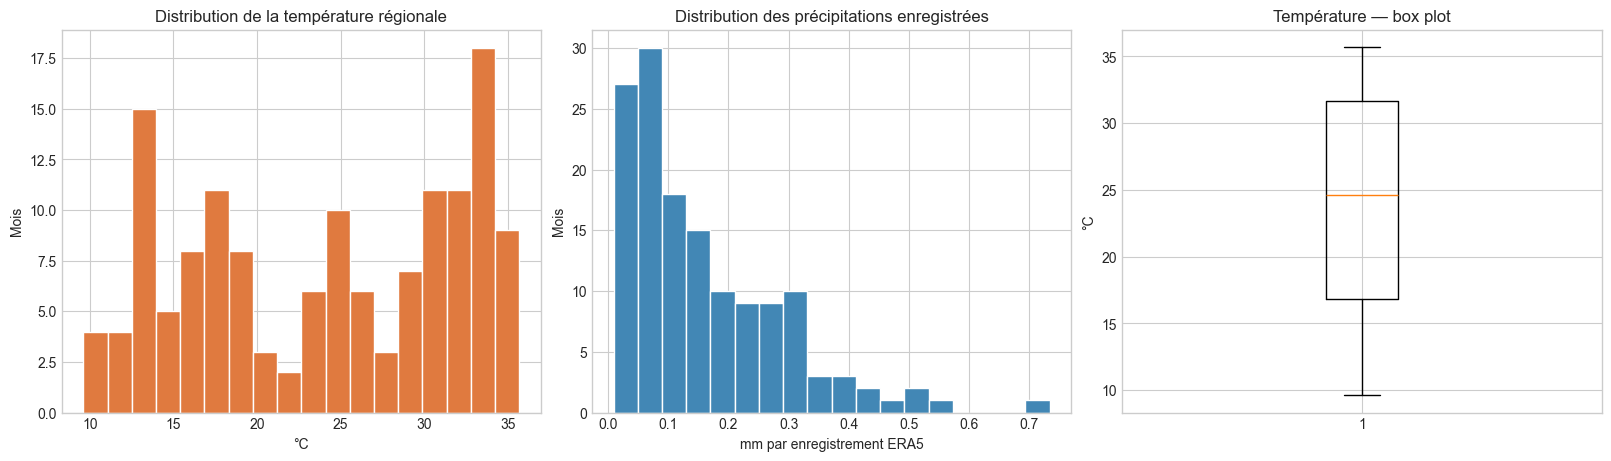

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
focus["t2m"].hist(ax=axes[0], bins=18, color="#e07a3f", edgecolor="white")
axes[0].set(title="Distribution de la température régionale", xlabel="°C", ylabel="Mois")
focus["tp"].hist(ax=axes[1], bins=18, color="#4287b5", edgecolor="white")
axes[1].set(title="Distribution des précipitations enregistrées", xlabel="mm par enregistrement ERA5", ylabel="Mois")
axes[2].boxplot(focus["t2m"].dropna(), vert=True)
axes[2].set(title="Température — box plot", ylabel="°C")
plt.show()

## Série temporelle et saisonnalité
Comme la précision temporelle change le motif visible, nous affichons l'évolution de la température et de l'humidité près de la surface, puis la moyenne de chaque mois calendaire sur les années. Les valeurs mensuelles source ne sont pas réagrégées ici.

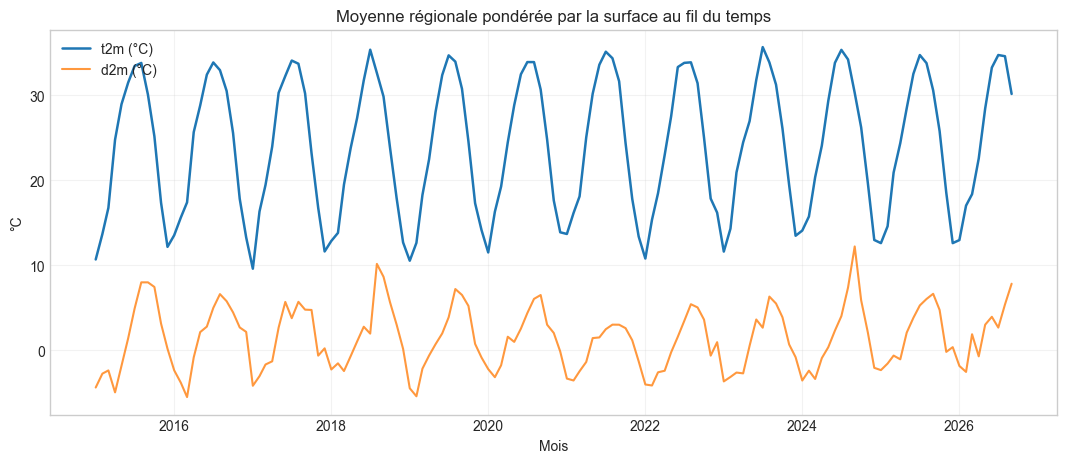

,t2m,d2m,tp
calendar_month,,,
1,12.06,-3.20,0.17
2,15.15,-3.07,0.16
3,19.00,-2.13,0.29
4,24.07,-1.32,0.22
5,28.62,1.09,0.16
6,32.62,2.85,0.08
7,34.59,3.72,0.03
8,33.83,6.46,0.09
9,30.64,6.72,0.21


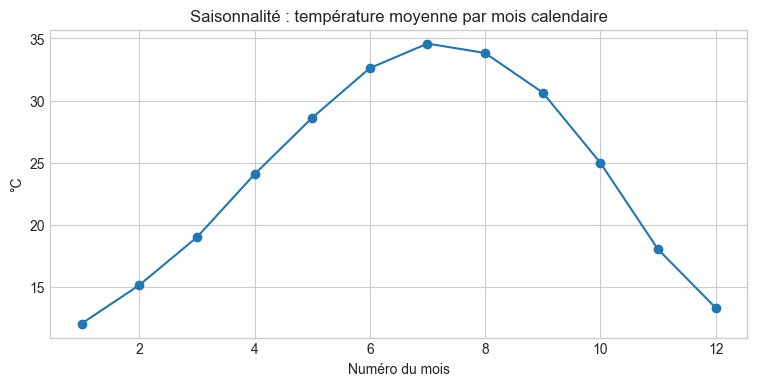

In [5]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(regional.index, regional["t2m"], label="t2m (°C)", linewidth=1.8)
if "d2m" in regional:
    ax.plot(regional.index, regional["d2m"], label="d2m (°C)", alpha=0.8)
ax.set(title="Moyenne régionale pondérée par la surface au fil du temps", xlabel="Mois", ylabel="°C")
ax.legend(); ax.grid(alpha=.25); plt.show()
monthly_climatology = regional.groupby(regional.index.month)[["t2m", "d2m", "tp"]].mean()
monthly_climatology.index.name = "calendar_month"
display(monthly_climatology.round(2))
monthly_climatology["t2m"].plot(marker="o", figsize=(9, 4), title="Saisonnalité : température moyenne par mois calendaire")
plt.xlabel("Numéro du mois"); plt.ylabel("°C"); plt.show()

## Valeurs extrêmes et classes
Nous utilisons la règle 1.5×IQR pour identifier les mois méritant un examen, et non pour les supprimer automatiquement. Les valeurs climatiques extrêmes peuvent être réelles. Pour appliquer le concept de binning, nous divisons les mois de température en trois classes selon les tertiles de la distribution ; ce sont des classes descriptives uniquement, et non des étiquettes d'entraînement ou des seuils climatiques standard.

In [6]:
q1, q3 = regional["t2m"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_months = regional.loc[(regional["t2m"] < lower) | (regional["t2m"] > upper), ["t2m"]]
print(f"Limites descriptives IQR : {lower:.2f}°C à {upper:.2f}°C ; mois méritant un examen : {len(outlier_months)}")
display(outlier_months)
regional["t2m_quantile_bin"] = pd.qcut(regional["t2m"], q=3, labels=["tertile inférieur", "tertile moyen", "tertile supérieur"], duplicates="drop")
display(regional["t2m_quantile_bin"].value_counts(sort=False).rename("Nombre de mois"))

Limites descriptives IQR : -5.52°C à 53.99°C ; mois méritant un examen : 0


,t2m
valid_time,


t2m_quantile_bin
tertile inférieur    47
tertile moyen        47
tertile supérieur    47
Name: Nombre de mois, dtype: int64

## Analyse multivariée : corrélation et carte thermique
La corrélation mesure une relation linéaire entre les séries régionales, et non la causalité. La saisonnalité peut gonfler les corrélations ; par conséquent, la carte doit être lue comme une description préliminaire, avec la nécessité d'une analyse des anomalies saisonnières si la question porte sur la relation après avoir supprimé le cycle annuel.

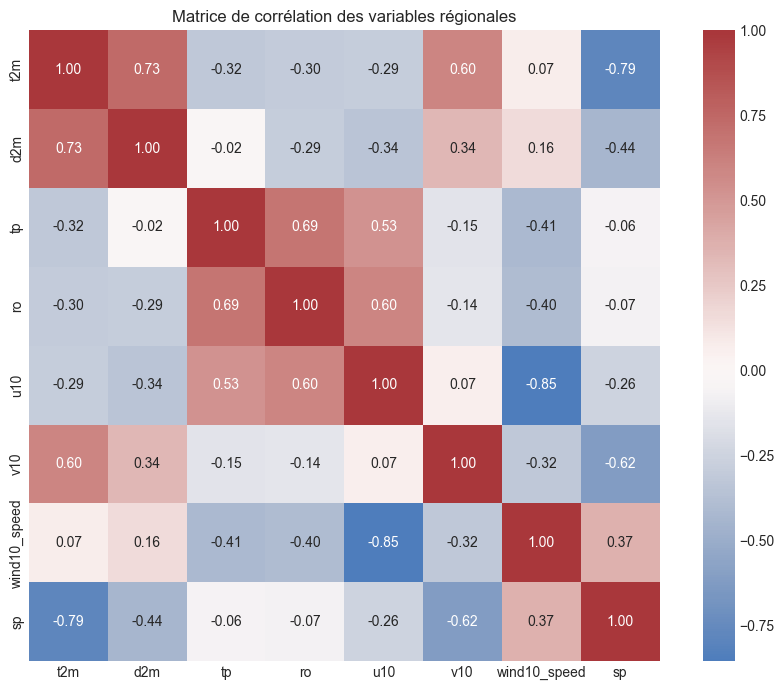

In [7]:
corr_cols = [c for c in ["t2m", "d2m", "tp", "ro", "u10", "v10", "wind10_speed", "sp"] if c in regional.columns]
corr = regional[corr_cols].corr(method="pearson")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Matrice de corrélation des variables régionales")
plt.tight_layout(); plt.show()